In [1]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
from halcyon.Simulators.GNWSimRunner import GNWSimRunner
from halcyon.Models.NeuralODE import PhoenixOnlyAddLayers, PhoenixAddAndProdLayers
from halcyon.Models.CellBox import CellBox

# import torch.multiprocessing as mp
import multiprocessing as mp

from halcyon.Trainer import TrainingJob, run_training_job

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import logging

import torch
import numpy as np
import random

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 


logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

In [2]:
# nr_genes_list = [32, 64, 128]
from halcyon.Simulators.GNWSimRunner import SimulationResult


nr_genes_list = [15]
# nr_modules_list = [16, 5, 10]
nr_modules_list = [3]
sparsity_list = [0.05]
out_path = Path("../data/hybrid_model_first_tests") 
sim_outputs: SimulationResult = []
for nr_genes in nr_genes_list: 
    for nr_modules in nr_modules_list: 
        for sparsity in sparsity_list: 
            gnw_sim = GNWSimRunner(
                settings_path=Path("../setting_files/gnw_testing_runs_settings.txt"),
            )
            generated_data_path = out_path / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
            generated_data_path.mkdir(parents=True, exist_ok=True)
            network_name = 'my_network'
            sim_result = gnw_sim.run_simulation(
                n_genes=nr_genes,
                sparsity=sparsity,
                num_modules=nr_modules,
                network_name=network_name,
                output_path=generated_data_path,
                keep_self_interactions=False
            )
            sim_outputs.append(sim_result) 
sim_outputs

2025-11-06 12:51:41,881 - INFO - Generating network
2025-11-06 12:51:42,607 - INFO - Simulating network expression over time


[SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_15_modules_3_sparsity_0.05'), network_name='my_network', nr_genes=15, nr_modules=3, sparsity=0.05, keep_self_interactions=False, network=<networkx.classes.digraph.DiGraph object at 0x7f87ec966950>)]

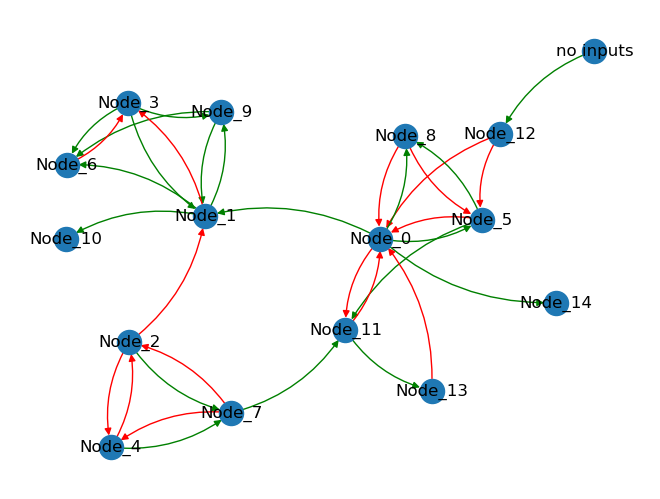

In [3]:
sim_outputs[0].plot_network()